# Figure 2

Panels D and E: power spectra of the naturalistic stimuli, the low-pass filter mixture, and the eight frequency bands for several exponents.
Panels A (movie frames, Chicago Motion Database), B (spectra digitized from Salisbury & Palmer, 2016) and C (schematic) are not made here.

No data needed: the stimuli come from the band-limited power law (Methods) and the low-pass mixture is fitted here.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy.optimize import least_squares

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['axes.titlesize'] = 12
matplotlib.rcParams['axes.labelsize'] = 12
matplotlib.rcParams['xtick.labelsize'] = 12
matplotlib.rcParams['ytick.labelsize'] = 12
matplotlib.rcParams['legend.fontsize'] = 12
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.rm'] = 'Arial'
matplotlib.rcParams['mathtext.it'] = 'Arial:italic'

# Paths
PATH_PDF = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)

In [2]:
COLOR_REF = {'blue': '#1c75bc', 'red': '#ef4237',
             'green': '#808233', 'yellow': '#f6eb16', 'orange': '#faa51a'}

C_NOISE, C_NAT = '0.65', 'k'
C_FIT, C_LAW = COLOR_REF['orange'], COLOR_REF['blue']
CMAP = LinearSegmentedColormap.from_list(
    'ref_blue_yellow_red', ['#0d3b66', COLOR_REF['blue'], COLOR_REF['yellow'],
                            COLOR_REF['orange'], COLOR_REF['red']])

N_ORDER = 4  # order of the band-pass filter
EXPONENTS = [-1.0, -1.3, -1.6, -1.8, -2.0]  # k
K_REF = -1.6
BAND_REF = (0.1, 10.0)  # Hz, Fig. 2D and Fig. 2E right

# eight two-decade bands (f_L, f_H) in Hz, with the time step dt (s) and length N of their grid
BANDS = [((1e-2, 1e0), 0.01, 2**15),
         ((10 ** -1.95, 10 ** -1.95 * 100), 0.01, 2**15),
         ((10 ** (-5 / 3), 10 ** (1 / 3)), 0.01, 2**15),
         ((10 ** (-4 / 3), 10 ** (2 / 3)), 0.01, 2**15),
         ((1e-1, 1e1), 0.01, 2**15),
         ((10 ** (-2 / 3), 10 ** (4 / 3)), 0.01, 2**15),
         ((10 ** (-1 / 3), 10 ** (5 / 3)), 0.01, 2**15),
         ((1e0, 1e2), 0.001, 2**19)]
GRID = {band: (dt, N) for band, dt, N in BANDS}


def k_label(k):
    return f'$k$ = −{-k:g}'


def strip_spines(ax, keep=('left', 'bottom')):
    for side in ('top', 'right', 'left', 'bottom'):
        ax.spines[side].set_visible(side in keep)


def log_decimate(f, npts=4000):
    # indices of ~npts log-spaced samples (plotting only)
    probe = np.logspace(np.log10(f[0]), np.log10(f[-1]), npts)
    return np.unique(np.clip(np.searchsorted(f, probe), 0, len(f) - 1))


def band_pass(f, band):  # Butterworth, order N_ORDER
    WL, WH = band
    Omega, w0, B = 2 * np.pi * np.asarray(f, dtype=float), 2 * np.pi * np.sqrt(WL * WH), 2 * np.pi * (WH - WL)
    return 1 / np.sqrt(1 + ((Omega ** 2 - w0 ** 2) / (B * Omega + np.spacing(1))) ** (2 * N_ORDER))


def power_law_spectrum(f, band, k):  # sigma_W = f_0 = 1
    f = np.asarray(f, dtype=float)
    with np.errstate(divide='ignore'):
        S = np.where(f > 0, f ** k, 0.0)
    return S * band_pass(f, band) ** 2


def band_spectrum(band, k):
    # S(f) on the band's own DFT grid, non-negative frequencies
    dt, N = GRID[band]
    f = (2 * np.pi * np.arange(N) / N) / (2 * np.pi) / dt
    S = power_law_spectrum(np.minimum(f, 1.0 / dt - f), band, k)
    return np.fft.rfftfreq(N, d=dt), S[:N // 2 + 1]


def mixture_spectrum(f, taus, alphas, band):
    # |h_s(f)|^2 |h_BP(f)|^2, h_s = sum_i alpha_i exp(-t / tau_i)
    Omega = 2 * np.pi * np.asarray(f, dtype=float)
    H = np.abs(sum(a / (1 + 1j * Omega * t) for t, a in zip(taus, alphas))) ** 2
    return H * band_pass(f, band) ** 2

In [3]:
def fit_mixture_canonical(band, k, n_freq=200):
    # least squares on log10 S over the band, tau_i and alpha_i fitted as log10
    WL, WH = band
    f_fit = np.logspace(np.log10(WL), np.log10(WH), n_freq)
    S_target = f_fit ** k * band_pass(f_fit, band) ** 2
    target_log = np.log10(S_target)

    def residuals(theta):
        model = mixture_spectrum(f_fit, 10.0 ** theta[:3], 10.0 ** theta[3:], band)
        return np.log10(model + 1e-300) - target_log

    tau_fast, tau_slow = 1 / (2 * np.pi * WH), 1 / (2 * np.pi * WL)
    tau_mid = np.sqrt(tau_fast * tau_slow)
    scale = np.sqrt(S_target[n_freq // 2])
    starts = [np.log10([tau_fast, tau_mid, tau_slow, scale, scale, scale]),
              np.log10([tau_mid, tau_mid, tau_mid, scale, scale, scale])]
    lb = np.log10([tau_fast * 1e-2] * 3 + [scale * 1e-10] * 3)
    ub = np.log10([tau_slow * 1e+2] * 3 + [scale * 1e+10] * 3)

    best = None
    for theta0 in starts:
        res = least_squares(residuals, np.clip(theta0, lb + 1e-9, ub - 1e-9), bounds=(lb, ub),
                            xtol=1e-13, ftol=1e-13, gtol=1e-13, max_nfev=5000)
        if best is None or res.cost < best.cost:
            best = res

    taus, alphas = 10.0 ** best.x[:3], 10.0 ** best.x[3:]
    order = np.argsort(taus)
    return tuple(taus[order]), tuple(alphas[order])


def fit_mixture(band, k):
    # fit on (1, f_H/f_L) Hz, then rescale by c = f_L
    WL, WH = band
    taus, alphas = fit_mixture_canonical((1.0, round(WH / WL, 9)), k)
    c = WL
    return tuple(t / c for t in taus), tuple(a * c ** (k / 2) for a in alphas)

## Fig. 2D

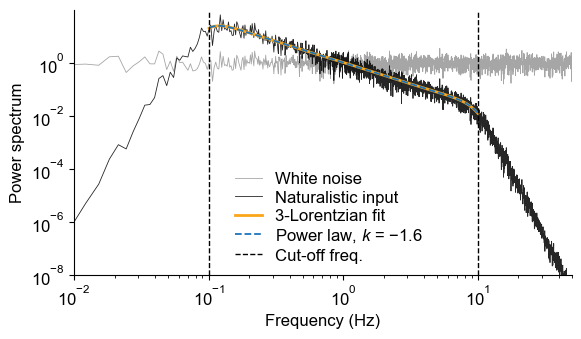

In [4]:
def plot_mixture(band, k, seed=0, n_avg=5):
    f, S_law = band_spectrum(band, k)
    f, S_law = f[1:], S_law[1:]
    dt, N = GRID[band]
    taus, alphas = fit_mixture(band, k)

    Omega = 2 * np.pi * f
    H = sum(a / (1 + 1j * Omega * t) for t, a in zip(taus, alphas)) * band_pass(f, band)
    rng = np.random.default_rng(seed)
    P_white, P_filt = np.zeros_like(f), np.zeros_like(f)
    for _ in range(n_avg):
        W = np.fft.rfft(rng.normal(0.0, 1.0, N))[1:]
        P_white += np.abs(W) ** 2 / N
        P_filt += np.abs(W * H) ** 2 / N
    P_white, P_filt = P_white / n_avg, P_filt / n_avg
    S_model = mixture_spectrum(f, taus, alphas, band)

    idx = log_decimate(f)
    in_band = idx[(f[idx] >= band[0]) & (f[idx] <= band[1])]
    Fig, ax = plt.subplots(figsize=(6.0, 3.4))
    Fig.subplots_adjust(left=0.15, right=0.98, top=0.96, bottom=0.18)
    ax.loglog(f[idx], P_white[idx], color=C_NOISE, lw=0.6, label='White noise')
    ax.loglog(f[idx], P_filt[idx], color=C_NAT, lw=0.6, alpha=0.85, label='Naturalistic input')
    ax.loglog(f[in_band], S_model[in_band], color=C_FIT, lw=2, label='3-Lorentzian fit')
    ax.loglog(f[in_band], S_law[in_band], '--', color=C_LAW, lw=1.3,
              label=f'Power law, {k_label(k)}')
    for edge in band:
        ax.axvline(edge, color='k', ls='--', lw=1)
    ax.plot([], [], color='k', ls='--', lw=1, label='Cut-off freq.')

    ax.set_xlim(max(f[0], band[0] / 10), min(f[-1], band[1] * 10))
    ax.set_ylim(1e-8, 1e2)
    ax.set_yticks([1e-8, 1e-6, 1e-4, 1e-2, 1e0])
    strip_spines(ax)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power spectrum')
    ax.legend(loc='lower left', bbox_to_anchor=(0.30, 0.0), frameon=False, handlelength=1.6,
              labelspacing=0.2, borderaxespad=0.3)
    return Fig


Fig = plot_mixture(BAND_REF, K_REF)
Fig.savefig(PATH_PDF / 'Fig2D_StimulusSpectrum_LowPassMixture.pdf', bbox_inches='tight')
plt.show()

## Fig. 2E

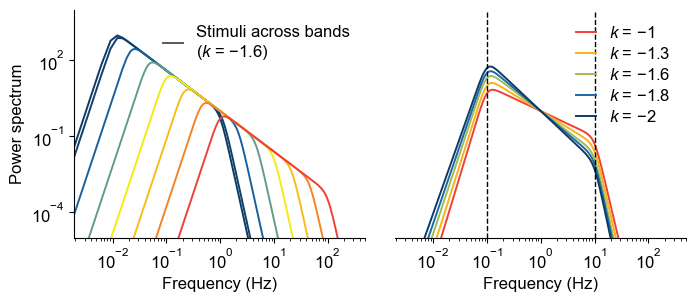

In [5]:
def decimated_spectrum(band, k, npts=400):
    f, S = band_spectrum(band, k)
    f, S = f[1:], S[1:]
    idx = log_decimate(f, npts)
    return f[idx], S[idx]


def full_curve(band, k, f_min, f_max, npts=200):
    # the band's own grid, completed by the power law below its df and above its Nyquist frequency
    f_sim, S_sim = decimated_spectrum(band, k)
    fs, Ss = [f_sim], [S_sim]
    if f_min < f_sim[0]:
        f_lo = np.logspace(np.log10(f_min), np.log10(f_sim[0]), npts, endpoint=False)
        fs.insert(0, f_lo), Ss.insert(0, power_law_spectrum(f_lo, band, k))
    if f_max > f_sim[-1]:
        f_hi = np.logspace(np.log10(f_sim[-1]), np.log10(f_max), npts + 1)[1:]
        fs.append(f_hi), Ss.append(power_law_spectrum(f_hi, band, k))
    return np.concatenate(fs), np.concatenate(Ss)


f_min = min(1.0 / (N * dt) for dt, N in GRID.values())
f_max = max(1.0 / (2 * dt) for dt, N in GRID.values())

Fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(7.2, 3.0), sharey=True)
Fig.subplots_adjust(left=0.13, right=0.98, top=0.96, bottom=0.20, wspace=0.10)

# left: the eight bands at k = -1.6, coloured by band centre
centres = [np.sqrt(lo * hi) for (lo, hi), _, _ in BANDS]
norm = plt.Normalize(np.log10(min(centres)), np.log10(max(centres)))
for (band, _, _), centre in zip(BANDS, centres):
    ax_left.loglog(*full_curve(band, K_REF, f_min, f_max), lw=1.4,
                   color=CMAP(norm(np.log10(centre))))
ax_left.legend(handles=[Line2D([0], [0], color='0.35', lw=1.4)],
               labels=[f'Stimuli across bands\n({k_label(K_REF)})'],
               loc='upper right', frameon=False, handlelength=1.2)

# right: the 0.1-10 Hz band at every exponent
norm_k = plt.Normalize(min(EXPONENTS), max(EXPONENTS))
for k in EXPONENTS:
    ax_right.loglog(*full_curve(BAND_REF, k, f_min, f_max), lw=1.4,
                    color=CMAP(norm_k(k)), label=k_label(k))
for edge in BAND_REF:
    ax_right.axvline(edge, color='k', ls='--', lw=1)
ax_right.legend(loc='upper right', frameon=False, handlelength=1.2, labelspacing=0.3)

for ax in (ax_left, ax_right):
    strip_spines(ax)
    ax.set_xlim(f_min, f_max)
    ax.set_xlabel('Frequency (Hz)')
ax_left.set_ylim(1e-5, 1e4)
ax_left.set_yticks([1e-4, 1e-1, 1e2])
ax_left.set_ylabel('Power spectrum')
strip_spines(ax_right, keep=('bottom',))
ax_right.tick_params(axis='y', length=0)
Fig.savefig(PATH_PDF / 'Fig2E_StimulusSpectra_BandsAndExponents.pdf', bbox_inches='tight')
plt.show()